# Preprocess và nội suy dữ liệu landmark dance

Notebook này chạy **một lần sau khi `extract_landmarks.py` tạo `landmarks.csv`**.

Nó sẽ:
1. Đọc và kiểm tra `landmarks.csv`.
2. Sắp xếp frame, xử lý frame trùng và chuyển các cột tọa độ sang kiểu số.
3. Nội suy tuyến tính **chỉ các khoảng thiếu ngắn nằm giữa hai frame có dữ liệu** (mặc định tối đa 5 frame liên tiếp) cho `x_i`, `y_i`, `z_i`.
4. Giữ nguyên `visibility_i` và cột `detected` gốc để không giả vờ rằng frame được nội suy là frame MediaPipe phát hiện thật.
5. Ghi `preprocessed_landmarks.csv` và tính góc khớp thành `joint_angles_preprocessed.csv`.

**Lưu ý:** Nội suy không sửa được landmark bị nhận diện sai nhưng vẫn có tọa độ. Notebook không tự làm mượt toàn bộ dữ liệu; trước hết ta chỉ xử lý giá trị thiếu để tránh làm biến dạng động tác. Các khoảng thiếu dài hơn giới hạn sẽ vẫn là NaN.

In [20]:
from pathlib import Path
import math
import numpy as np
import pandas as pd

# Đặt notebook cùng thư mục với landmarks.csv.
BASE_DIR = Path.cwd()
INPUT_PATH = BASE_DIR / "landmarks_student.csv"
LANDMARKS_OUTPUT_PATH = BASE_DIR / "preprocessed_landmarks_student.csv"
ANGLES_OUTPUT_PATH = BASE_DIR / "joint_angles_student.csv"

# Chỉ nội suy khoảng trống ngắn; đổi số này nếu cần sau khi kiểm tra dữ liệu.
MAX_GAP_FRAMES = 5

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy {INPUT_PATH}. Hãy đặt notebook cùng thư mục với landmarks.csv "
        "hoặc sửa INPUT_PATH trong cell này."
    )

df = pd.read_csv(INPUT_PATH)
print("Kích thước ban đầu:", df.shape)
print("Các cột đầu tiên:", df.columns[:12].tolist())
display(df.head())

Kích thước ban đầu: (377, 135)
Các cột đầu tiên: ['frame', 'timestamp_ms', 'detected', 'x_0', 'y_0', 'z_0', 'visibility_0', 'x_1', 'y_1', 'z_1', 'visibility_1', 'x_2']


,frame,timestamp_ms,detected,x_0,y_0,z_0,visibility_0,x_1,y_1,z_1,...,z_30,visibility_30,x_31,y_31,z_31,visibility_31,x_32,y_32,z_32,visibility_32
0,0,0,1,0.468988,0.282075,-0.189315,0.999921,0.484653,0.270976,-0.162307,...,0.436126,0.806218,0.525226,0.859496,-0.216148,0.952208,0.380769,0.852001,0.194078,0.942317
1,1,33,1,0.467636,0.279750,-0.202267,0.999909,0.483464,0.268882,-0.178499,...,0.427737,0.804620,0.537719,0.859570,-0.134174,0.950899,0.382171,0.852098,0.180711,0.942330
2,2,66,1,0.465851,0.278552,-0.235188,0.999894,0.481643,0.267770,-0.212434,...,0.495968,0.805483,0.536789,0.858967,-0.158595,0.951187,0.382183,0.852079,0.243212,0.942804
3,3,100,1,0.465873,0.278478,-0.226472,0.999885,0.481659,0.267684,-0.203576,...,0.501691,0.805186,0.524604,0.859367,-0.185983,0.950827,0.382150,0.852113,0.260000,0.941573
4,4,133,1,0.464713,0.278501,-0.222854,0.999881,0.480617,0.267626,-0.198576,...,0.473811,0.806550,0.528974,0.859363,-0.156157,0.950276,0.381573,0.852321,0.231114,0.941888


## 1. Chuẩn hóa bảng dữ liệu

- `frame` phải là số nguyên và được sắp xếp tăng dần.
- Nếu có nhiều dòng cùng `frame`, giữ dòng cuối cùng.
- Chỉ các cột tọa độ được nội suy. `visibility` và `detected` được giữ nguyên để có thể phân biệt dữ liệu thật với dữ liệu được ước lượng.

In [ ]:
if "frame" not in df.columns:
    raise ValueError("CSV không có cột 'frame'.")

df["frame"] = pd.to_numeric(df["frame"], errors="coerce")
df = df.dropna(subset=["frame"]).copy()
df["frame"] = df["frame"].astype(int)
df = df.sort_values("frame").drop_duplicates(subset=["frame"], keep="last").reset_index(drop=True)

if "timestamp_ms" in df.columns:
    df["timestamp_ms"] = pd.to_numeric(df["timestamp_ms"], errors="coerce")

if "detected" in df.columns:
    # Chuẩn hóa thành số nếu có thể, nhưng không thay đổi ý nghĩa cột.
    df["detected"] = pd.to_numeric(df["detected"], errors="coerce")

landmark_ids = sorted({
    int(col.rsplit("_", 1)[1])
    for col in df.columns
    if col.startswith("x_") and col.rsplit("_", 1)[1].isdigit()
})

if not landmark_ids:
    raise ValueError("Không tìm thấy cột tọa độ dạng x_0, x_1, ...")

coordinate_columns = []
for i in landmark_ids:
    for axis in ("x", "y", "z"):
        col = f"{axis}_{i}"
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
            coordinate_columns.append(col)

visibility_columns = [
    f"visibility_{i}" for i in landmark_ids
    if f"visibility_{i}" in df.columns
]
for col in visibility_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Số frame sau chuẩn hóa: {len(df)}")
print(f"Số landmark tìm thấy: {len(landmark_ids)}")
print(f"Số cột tọa độ: {len(coordinate_columns)}")
print("Số giá trị tọa độ thiếu trước nội suy:", int(df[coordinate_columns].isna().sum().sum()))

Số frame sau chuẩn hóa: 377
Số landmark tìm thấy: 33
Số cột tọa độ: 99
Số giá trị tọa độ thiếu trước nội suy: 0


## 2. Nội suy các khoảng thiếu ngắn

Nội suy tuyến tính theo thứ tự frame, chỉ lấp các khoảng thiếu **nằm giữa** hai giá trị hợp lệ (`limit_area="inside"`). `limit=MAX_GAP_FRAMES` giới hạn số frame thiếu liên tiếp được lấp. Những khoảng thiếu ở đầu/cuối video hoặc dài hơn giới hạn sẽ không bị điền bằng giá trị phỏng đoán.

In [22]:

# Ngưỡng visibility và giới hạn nội suy
VISIBILITY_THRESHOLD = 0.5
MAX_GAP_FRAMES = 5

# Dùng dữ liệu landmarks đã chuẩn hóa ở cell trước
df_clean = df.copy()

# Đảm bảo các cột tọa độ và visibility là kiểu số
for i in landmark_ids:
    for axis in ("x", "y", "z"):
        col = f"{axis}_{i}"
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(
                df_clean[col], errors="coerce"
            )

    vis_col = f"visibility_{i}"
    if vis_col in df_clean.columns:
        df_clean[vis_col] = pd.to_numeric(
            df_clean[vis_col], errors="coerce"
        )

# Sắp xếp theo frame và tạo đủ các frame liên tiếp
df_clean = (
    df_clean.sort_values("frame")
    .drop_duplicates(subset=["frame"], keep="last")
    .set_index("frame")
)

full_frames = range(
    int(df_clean.index.min()),
    int(df_clean.index.max()) + 1
)
indexed = df_clean.reindex(full_frames)
indexed.index.name = "frame"

# Lưu lại các frame thực sự có trong CSV gốc
original_frames = set(df_clean.index)
indexed["frame_in_original_csv"] = (
    indexed.index.isin(original_frames).astype(int)
)

# Đánh dấu tọa độ không đáng tin cậy khi visibility < 0.5
invalid_count = 0

for i in landmark_ids:
    vis_col = f"visibility_{i}"
    coord_cols = [
        f"{axis}_{i}" for axis in ("x", "y", "z")
        if f"{axis}_{i}" in indexed.columns
    ]

    if vis_col not in indexed.columns or not coord_cols:
        continue

    low_visibility = (
        indexed[vis_col].isna()
        | (indexed[vis_col] < VISIBILITY_THRESHOLD)
    )

    invalid_count += int(low_visibility.sum())

    # Chỉ loại tọa độ của landmark không đáng tin cậy
    indexed.loc[low_visibility, coord_cols] = np.nan

# Nội suy từng cột tọa độ, chỉ lấp khoảng thiếu nằm giữa
# hai giá trị hợp lệ; không nội suy quá MAX_GAP_FRAMES liên tiếp.
coordinate_columns = [
    f"{axis}_{i}"
    for i in landmark_ids
    for axis in ("x", "y", "z")
    if f"{axis}_{i}" in indexed.columns
]

missing_before = indexed[coordinate_columns].isna().sum().sum()

for col in coordinate_columns:
    indexed[col] = indexed[col].interpolate(
        method="linear",
        limit=MAX_GAP_FRAMES,
        limit_area="inside"
    )

missing_after = indexed[coordinate_columns].isna().sum().sum()

# Giữ nguyên thông tin phát hiện gốc; frame được thêm không phải
# frame được MediaPipe phát hiện thật.
if "detected" in indexed.columns:
    new_frames = indexed["frame_in_original_csv"] == 0
    indexed.loc[new_frames, "detected"] = np.nan

# Gắn cờ frame có tọa độ thiếu sau nội suy
indexed["has_missing_coordinates"] = (
    indexed[coordinate_columns].isna().any(axis=1)
).astype(int)

df_processed = indexed.reset_index()

print("Số landmark-frame có visibility thấp/không xác định:", invalid_count)
print("Số ô tọa độ thiếu trước nội suy:", int(missing_before))
print("Số ô tọa độ thiếu sau nội suy:", int(missing_after))
print(
    "Số frame vẫn còn tọa độ thiếu:",
    int(df_processed["has_missing_coordinates"].sum())
)

display(df_processed.head())


Số landmark-frame có visibility thấp/không xác định: 1781
Số ô tọa độ thiếu trước nội suy: 5343
Số ô tọa độ thiếu sau nội suy: 5055
Số frame vẫn còn tọa độ thiếu: 259


C:\Users\Admin\AppData\Local\Temp\ipykernel_26980\2809620788.py:93: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  indexed["has_missing_coordinates"] = (


,frame,timestamp_ms,detected,x_0,y_0,z_0,visibility_0,x_1,y_1,z_1,...,x_31,y_31,z_31,visibility_31,x_32,y_32,z_32,visibility_32,frame_in_original_csv,has_missing_coordinates
0,0,0,1.0,0.468988,0.282075,-0.189315,0.999921,0.484653,0.270976,-0.162307,...,0.525226,0.859496,-0.216148,0.952208,0.380769,0.852001,0.194078,0.942317,1,0
1,1,33,1.0,0.467636,0.279750,-0.202267,0.999909,0.483464,0.268882,-0.178499,...,0.537719,0.859570,-0.134174,0.950899,0.382171,0.852098,0.180711,0.942330,1,0
2,2,66,1.0,0.465851,0.278552,-0.235188,0.999894,0.481643,0.267770,-0.212434,...,0.536789,0.858967,-0.158595,0.951187,0.382183,0.852079,0.243212,0.942804,1,0
3,3,100,1.0,0.465873,0.278478,-0.226472,0.999885,0.481659,0.267684,-0.203576,...,0.524604,0.859367,-0.185983,0.950827,0.382150,0.852113,0.260000,0.941573,1,0
4,4,133,1.0,0.464713,0.278501,-0.222854,0.999881,0.480617,0.267626,-0.198576,...,0.528974,0.859363,-0.156157,0.950276,0.381573,0.852321,0.231114,0.941888,1,0


## 3. Lưu dữ liệu landmark đã preprocess

File đầu ra giữ các cột landmark gốc, đồng thời thêm cột kiểm tra nội suy. Không ghi đè file `landmarks.csv` để luôn giữ bản gốc.

In [23]:
df_processed.to_csv(LANDMARKS_OUTPUT_PATH, index=False)
print("Đã lưu:", LANDMARKS_OUTPUT_PATH)
display(df_processed.head())

Đã lưu: d:\Danceup\DanceUp_App\python\preprocessed_landmarks_student.csv


,frame,timestamp_ms,detected,x_0,y_0,z_0,visibility_0,x_1,y_1,z_1,...,x_31,y_31,z_31,visibility_31,x_32,y_32,z_32,visibility_32,frame_in_original_csv,has_missing_coordinates
0,0,0,1.0,0.468988,0.282075,-0.189315,0.999921,0.484653,0.270976,-0.162307,...,0.525226,0.859496,-0.216148,0.952208,0.380769,0.852001,0.194078,0.942317,1,0
1,1,33,1.0,0.467636,0.279750,-0.202267,0.999909,0.483464,0.268882,-0.178499,...,0.537719,0.859570,-0.134174,0.950899,0.382171,0.852098,0.180711,0.942330,1,0
2,2,66,1.0,0.465851,0.278552,-0.235188,0.999894,0.481643,0.267770,-0.212434,...,0.536789,0.858967,-0.158595,0.951187,0.382183,0.852079,0.243212,0.942804,1,0
3,3,100,1.0,0.465873,0.278478,-0.226472,0.999885,0.481659,0.267684,-0.203576,...,0.524604,0.859367,-0.185983,0.950827,0.382150,0.852113,0.260000,0.941573,1,0
4,4,133,1.0,0.464713,0.278501,-0.222854,0.999881,0.480617,0.267626,-0.198576,...,0.528974,0.859363,-0.156157,0.950276,0.381573,0.852321,0.231114,0.941888,1,0


In [24]:

from scipy.signal import savgol_filter
import numpy as np
import pandas as pd

# Tham số lọc
WINDOW_LENGTH = 7  # Phải là số lẻ
POLYORDER = 2

df_filtered = df_processed.copy()

coordinate_columns = [
    f"{axis}_{i}"
    for i in landmark_ids
    for axis in ("x", "y", "z")
    if f"{axis}_{i}" in df_filtered.columns
]

for col in coordinate_columns:
    values = pd.to_numeric(
        df_filtered[col], errors="coerce"
    ).to_numpy(dtype=float)

    valid = np.isfinite(values)

    # Chia thành các đoạn liên tục có dữ liệu hợp lệ.
    # Không lọc xuyên qua khoảng NaN dài.
    starts = np.where(valid & ~np.r_[False, valid[:-1]])[0]
    ends = np.where(valid & ~np.r_[valid[1:], False])[0] + 1

    filtered_values = values.copy()

    for start, end in zip(starts, ends):
        segment = values[start:end]
        n = len(segment)

        # Chỉ lọc các đoạn đủ dài
        if n >= WINDOW_LENGTH:
            filtered_values[start:end] = savgol_filter(
                segment,
                window_length=WINDOW_LENGTH,
                polyorder=POLYORDER,
                mode="interp"
            )

    df_filtered[col] = filtered_values

print("Đã lọc nhiễu tọa độ 3D.")
print("Số frame:", len(df_filtered))
print(
    "Số ô tọa độ còn thiếu:",
    int(df_filtered[coordinate_columns].isna().sum().sum())
)


Đã lọc nhiễu tọa độ 3D.
Số frame: 377
Số ô tọa độ còn thiếu: 5055


## 4. Tính góc khớp từ dữ liệu đã preprocess

Các góc được tính bằng tọa độ 3D nhất quán. Nếu một trong ba điểm của khớp vẫn thiếu sau bước nội suy, góc tương ứng sẽ là `NaN` thay vì tự tạo ra tọa độ. `left_shoulder`/`right_shoulder` ở đây là góc giữa cánh tay và thân người (elbow–shoulder–hip), không phải phép đo toàn bộ chuyển động xoay của khớp vai.

In [25]:
def get_point(row, landmark_id):
    cols = [f"x_{landmark_id}", f"y_{landmark_id}", f"z_{landmark_id}"]
    if any(col not in row.index for col in cols):
        return np.array([np.nan, np.nan, np.nan], dtype=float)
    return np.array([pd.to_numeric(row[col], errors="coerce") for col in cols], dtype=float)

def calculate_angle(a, b, c):
    if not (np.isfinite(a).all() and np.isfinite(b).all() and np.isfinite(c).all()):
        return np.nan
    ba = a - b
    bc = c - b
    norm_ba = np.linalg.norm(ba)
    norm_bc = np.linalg.norm(bc)
    if norm_ba < 1e-8 or norm_bc < 1e-8:
        return np.nan
    cosine = np.dot(ba, bc) / (norm_ba * norm_bc)
    cosine = np.clip(cosine, -1.0, 1.0)
    return math.degrees(math.acos(cosine))

joints = {
    "left_elbow": (11, 13, 15),
    "right_elbow": (12, 14, 16),
    "left_shoulder": (13, 11, 23),
    "right_shoulder": (14, 12, 24),
    "left_knee": (23, 25, 27),
    "right_knee": (24, 26, 28),
}

angle_rows = []
for _, row in df_filtered.iterrows():
    result = {"frame": int(row["frame"])}
    if "timestamp_ms" in df_filtered.columns:
        result["timestamp_ms"] = row["timestamp_ms"]

    for name, (a_id, b_id, c_id) in joints.items():
        a = get_point(row, a_id)
        b = get_point(row, b_id)
        c = get_point(row, c_id)
        result[name] = calculate_angle(a, b, c)

    angle_rows.append(result)

angles_df = pd.DataFrame(angle_rows)
angles_df.to_csv(ANGLES_OUTPUT_PATH, index=False)

print("Đã lưu:", ANGLES_OUTPUT_PATH)
print("Số frame:", len(angles_df))
print("\n5 dòng đầu tiên:")
display(angles_df.head())

Đã lưu: d:\Danceup\DanceUp_App\python\joint_angles_student.csv
Số frame: 377

5 dòng đầu tiên:


,frame,timestamp_ms,left_elbow,right_elbow,left_shoulder,right_shoulder,left_knee,right_knee
0,0,0.0,134.253713,149.531885,60.227705,31.539746,115.869330,121.689406
1,1,33.0,134.379491,148.627808,65.281071,33.386293,107.106835,125.076927
2,2,66.0,134.426887,148.071748,69.079181,34.729234,103.026285,126.310097
3,3,100.0,134.419025,147.947760,71.465105,35.511155,103.105763,125.331720
4,4,133.0,133.148633,147.966827,72.035380,35.861308,108.921176,122.180276


## 5. Kiểm tra nhanh kết quả

Biểu đồ dưới đây chỉ để quan sát chuỗi góc sau nội suy. Nếu vẫn còn các cú nhảy lớn, không nên tiếp tục nội suy mạnh hơn ngay; hãy kiểm tra video/landmark ở những frame đó, vì nội suy chỉ xử lý giá trị thiếu chứ không phát hiện được tọa độ sai nhưng vẫn có số.

Đã lưu biểu đồ: d:\Danceup\DanceUp_App\python\joint_angles_preprocessed_plot.png


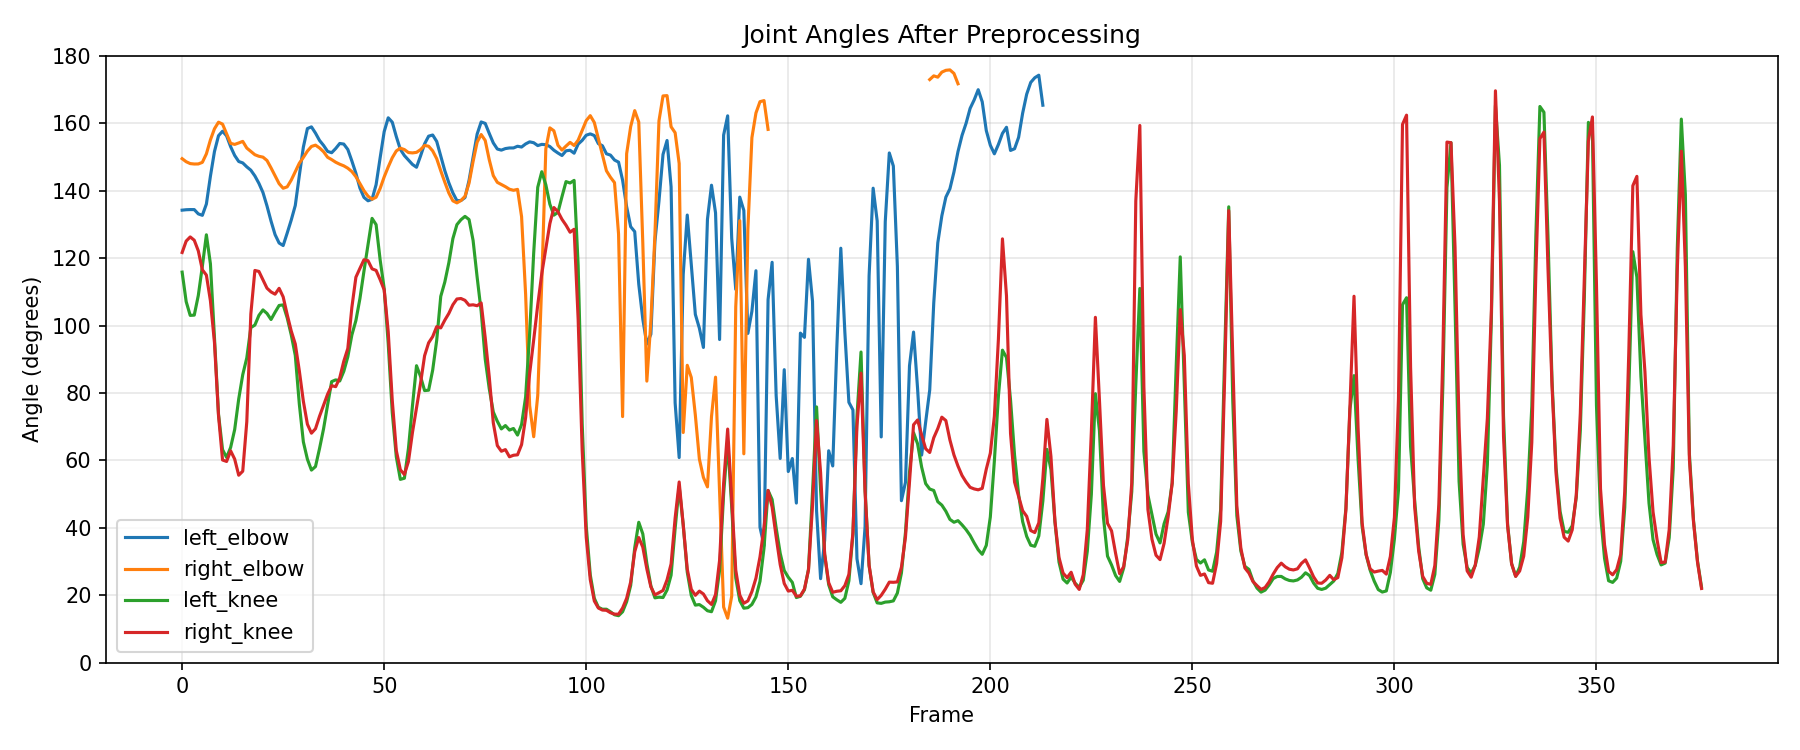

In [26]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

plot_path = BASE_DIR / "joint_angles_preprocessed_plot.png"
plot_joints = ["left_elbow", "right_elbow", "left_knee", "right_knee"]

fig, ax = plt.subplots(figsize=(12, 5))
for joint in plot_joints:
    ax.plot(angles_df["frame"], angles_df[joint], label=joint)

ax.set_title("Joint Angles After Preprocessing")
ax.set_xlabel("Frame")
ax.set_ylabel("Angle (degrees)")
ax.set_ylim(0, 180)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(plot_path, dpi=150)
plt.close(fig)

print("Đã lưu biểu đồ:", plot_path)
display(Image(filename=str(plot_path)))